In [ ]:
import numpy as np

# Modul sis (ako nije instaliran, npr. u Google Colab-u, instalira se automatski)
try:
    import sis
except ModuleNotFoundError:
    %pip install -q git+https://github.com/esokic/sis.git
    import sis

sis.FORMAT = "JUPYTER"    # prikaz grafika prilagodjen interaktivnom radu

In [2]:
# =========================================================
# Kod 5.1 - Signal f(t) iz primjera 5.4.
# =========================================================

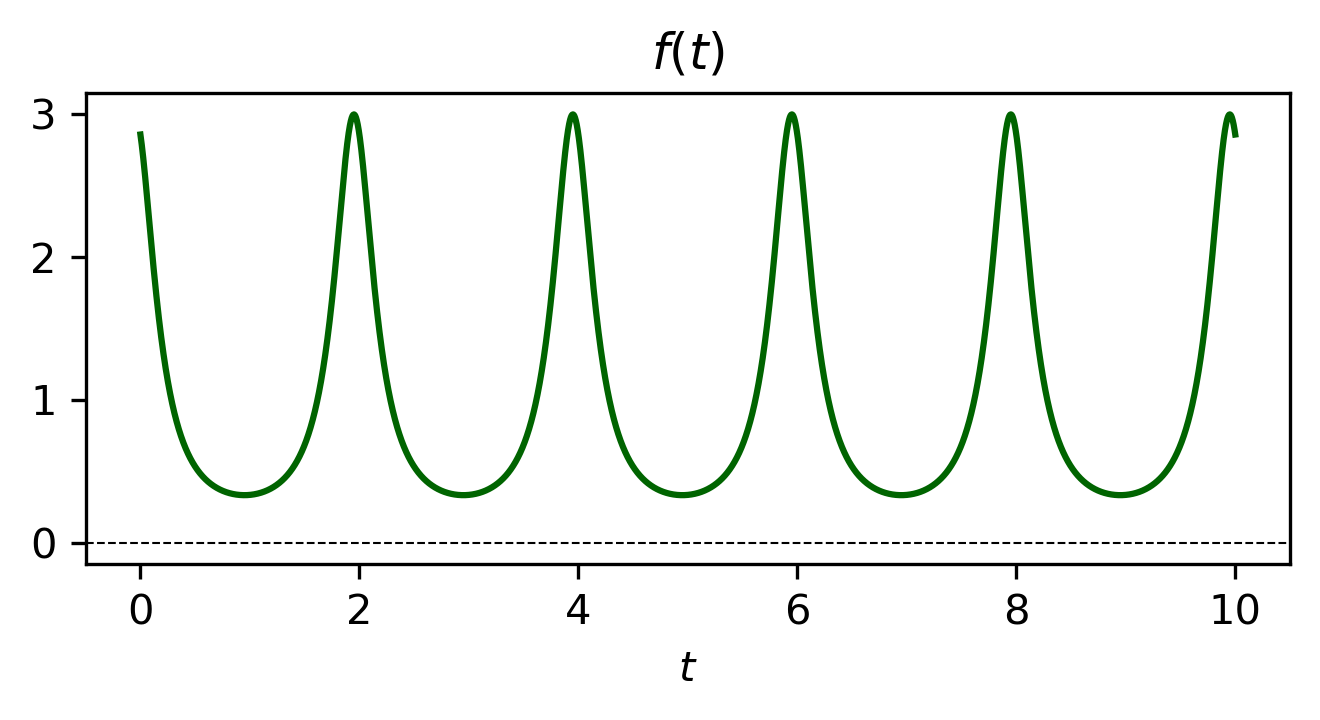

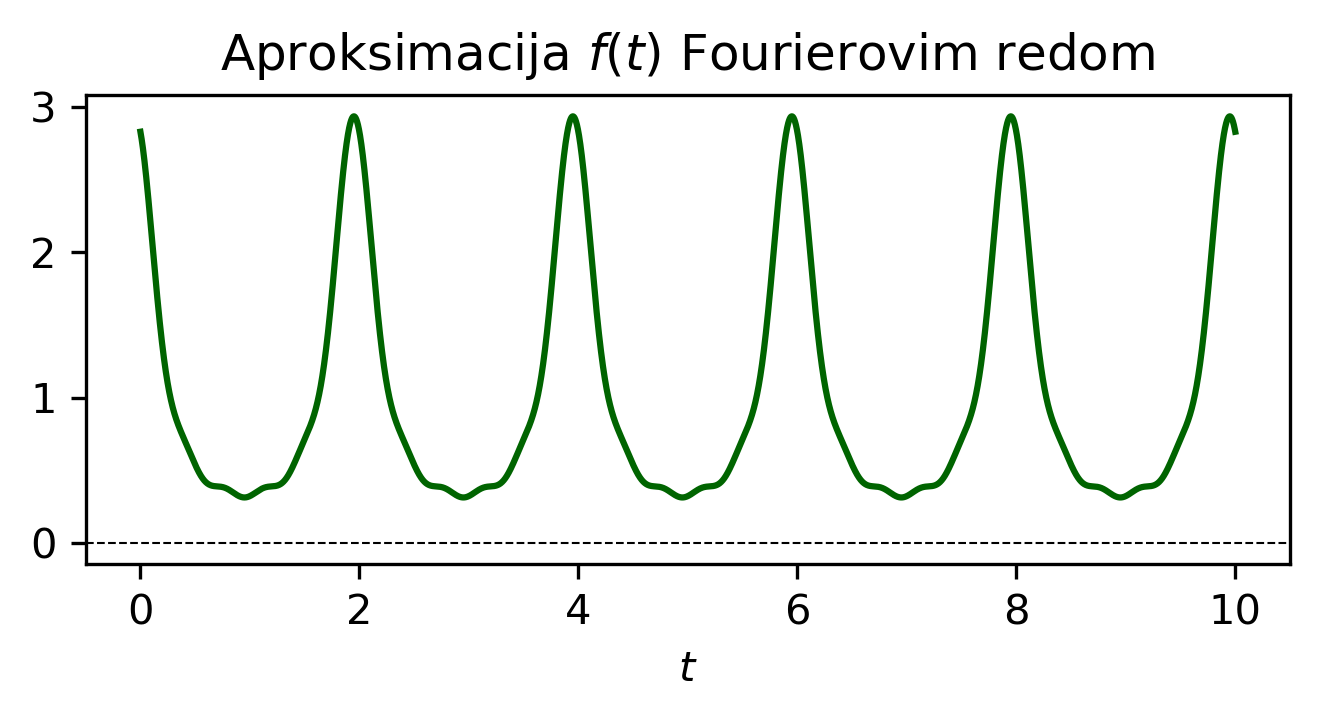

In [3]:
t = np.arange(0, 10.001, 0.001)
x1 = 3 / (5 - 4 * np.cos(np.pi * t + (np.pi / 20)))

sis.dijagram(t, x1, naslov='$f(t)$')

#aproksimacija sa M-harmonika
M = 5
w0 = np.pi

aproks = np.zeros(len(t))

for k in range(-M, M + 1):
    ck = ((0.5)**abs(k))* np.exp(1j* k * np.pi /20) 
    aproks = aproks +  ck * np.exp(1j* k * w0 * t)
                        
aproks = np.real(aproks)

sis.dijagram(t, aproks, naslov='Aproksimacija $f(t)$ Fourierovim redom') 

In [4]:
# =========================================================
# Kod 5.2 - Pomocna funkcija za formiranje originalnog signala
# =========================================================

In [5]:
def formiranje_signala(t, per, ts):
    """Formiranje pravougaonog periodicnog signala, duty cycle 50%."""
    x = np.zeros(len(t))
    gr = int(per / ts)             # broj tacaka jednog perioda
    sirina = int(per / (2 * ts))   # sirina impulsa = pola perioda
    for t0 in np.arange(t[0], t[-1], per):
        idx = int((t0 - t[0]) / ts)
        x[idx:idx + sirina] = 1
    return x, gr

In [6]:
# =========================================================
# Kod 5.3 - Aproksimacija sa prvih br harmonika
# =========================================================

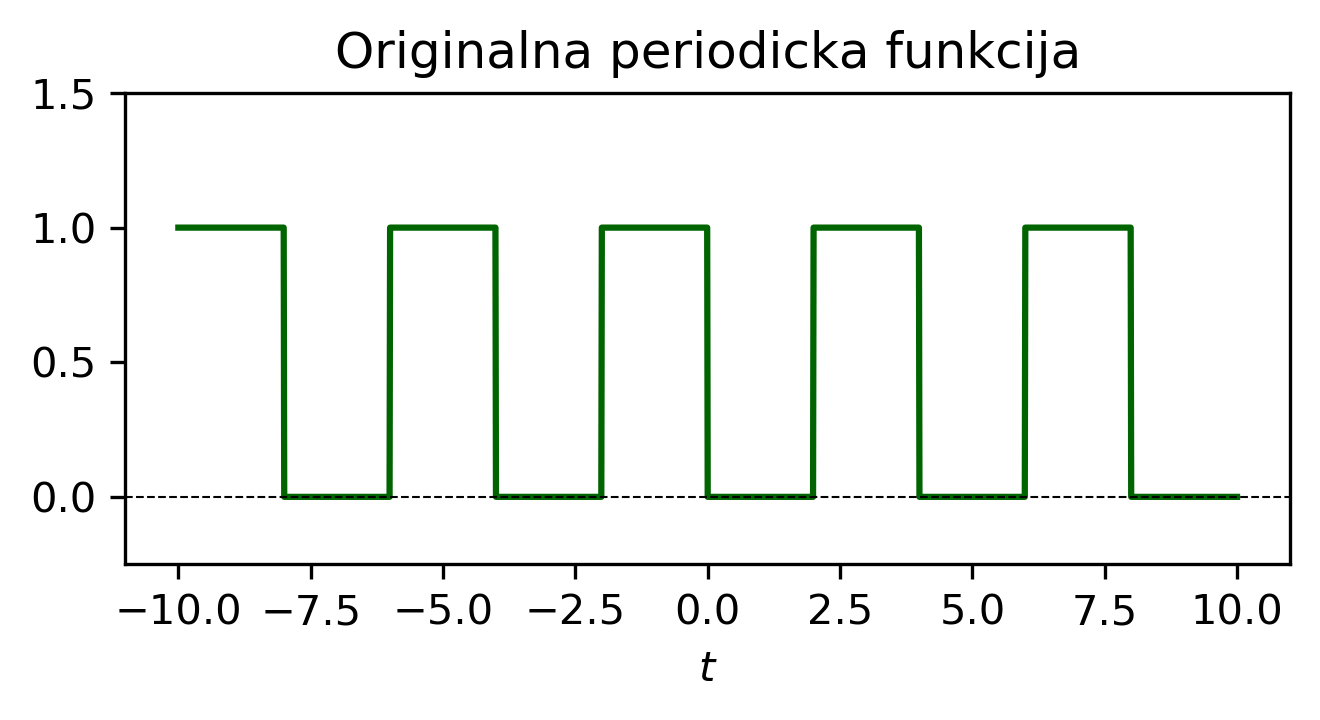

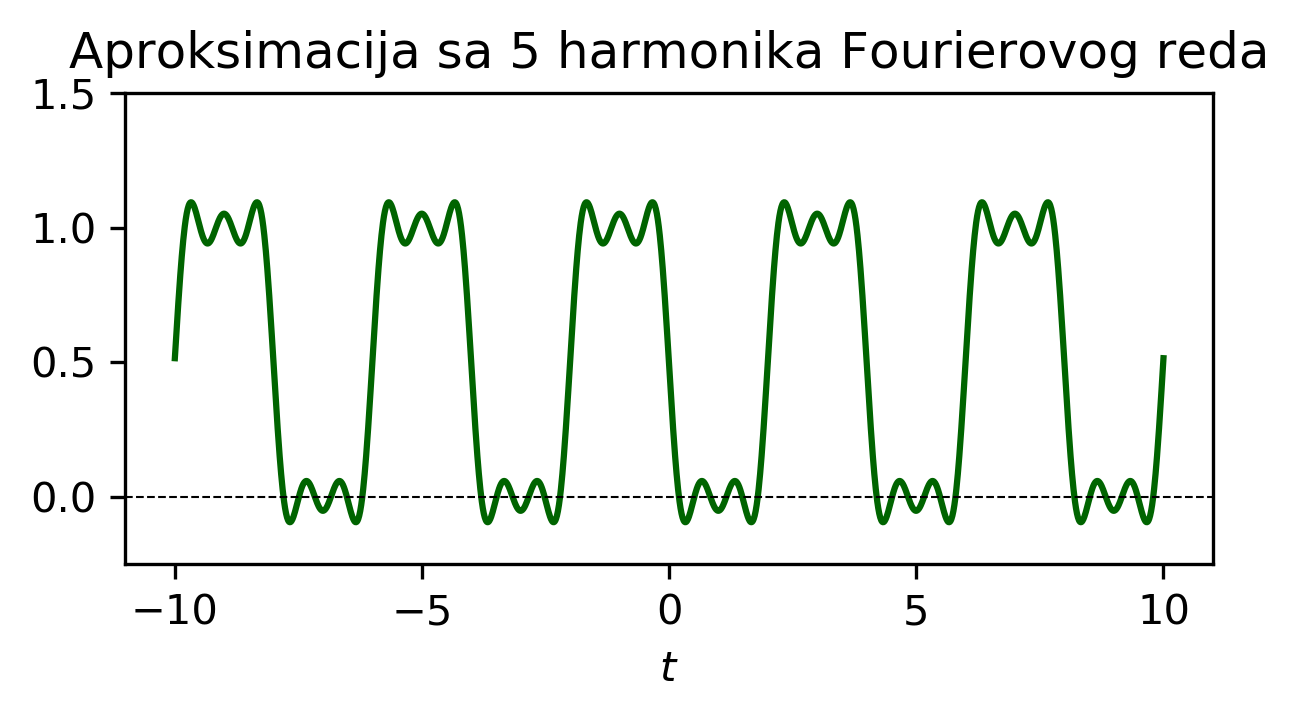

In [7]:
per = 4        # period signala
br  = 5        # broj harmonika
ts  = 0.01     # vremenski korak
t   = np.arange(-10, 10 + ts, ts)

x, gr = formiranje_signala(t, per, ts)

w0  = 2 * np.pi / per
osn = np.zeros(len(t))
osn[0:gr] = x[0:gr]          # jedan period originalne funkcije

# racunanje koeficijenata i aproksimacije
a = np.zeros(br)
b = np.zeros(br)
aproks = np.zeros(len(t))

for k in range(1, br + 1):
    a[k-1] = 2 * ts / per * np.sum(osn * np.cos(k * w0 * t))
    b[k-1] = 2 * ts / per * np.sum(osn * np.sin(k * w0 * t))
    aproks = aproks + (a[k-1] * np.cos(k * w0 * t)
                        + b[k-1] * np.sin(k * w0 * t))

a0 = 2 * ts / per * np.sum(osn)    # koeficijent a0
aproks = aproks + a0 / 2

sis.dijagram(t, x, 
             ylim=(-.25, 1.5),
             naslov='Originalna periodicka funkcija')

sis.dijagram(t, aproks, 
             ylim=(-.25, 1.5),
             naslov=f'Aproksimacija sa {br} harmonika Fourierovog reda')

In [8]:
# =========================================================
# Kod 5.4 - Pracenje oblika aproksimirane funkcije
#           u zavisnosti od broja harmonika
# =========================================================

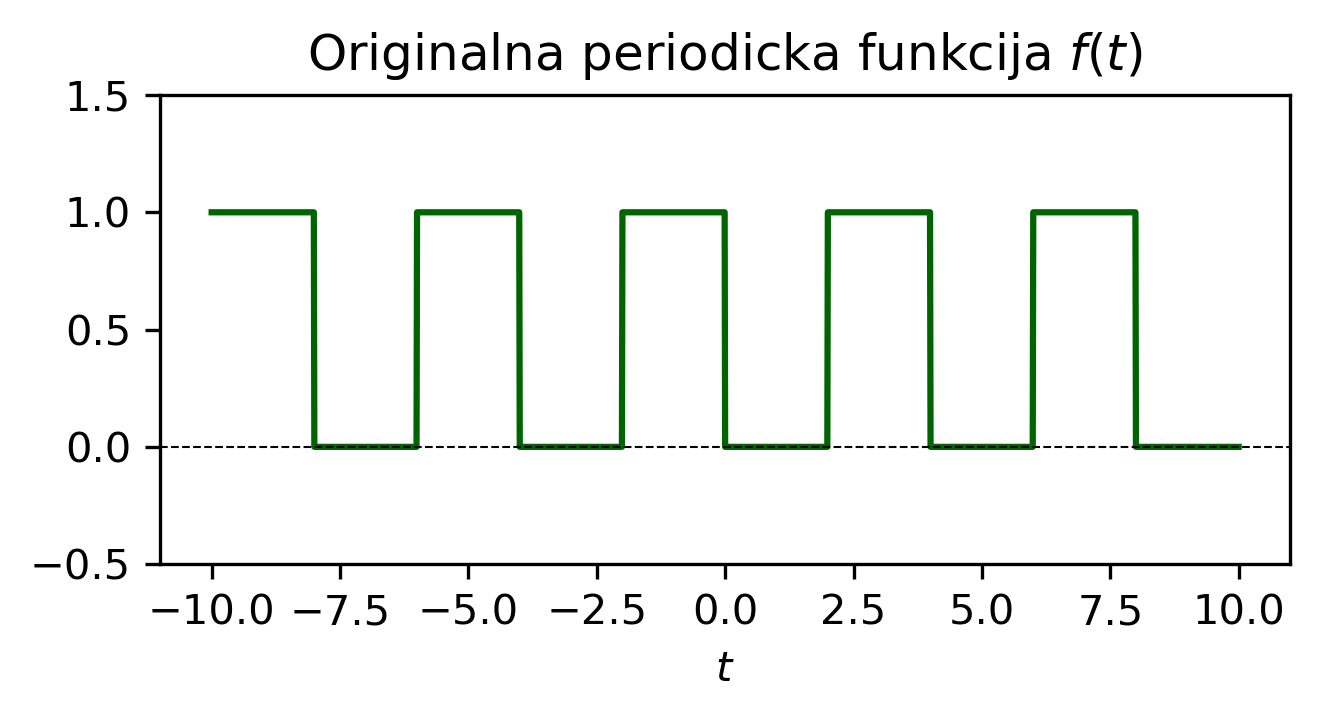

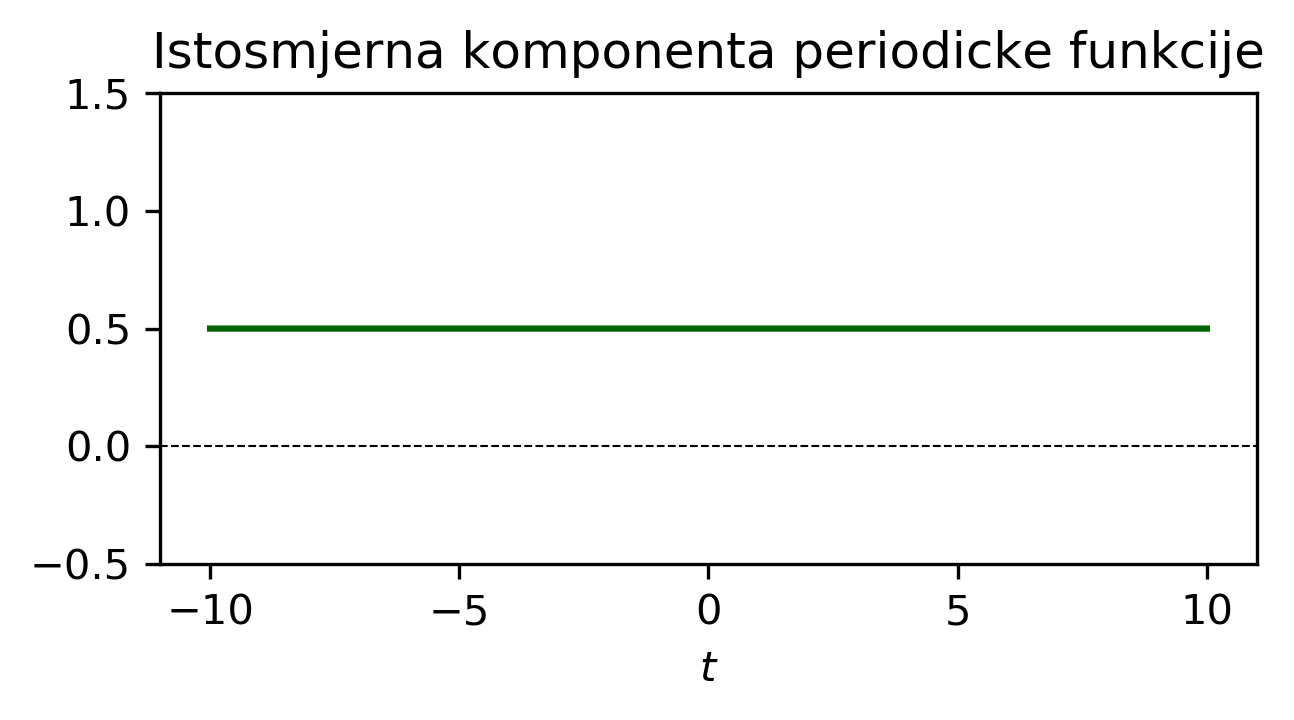

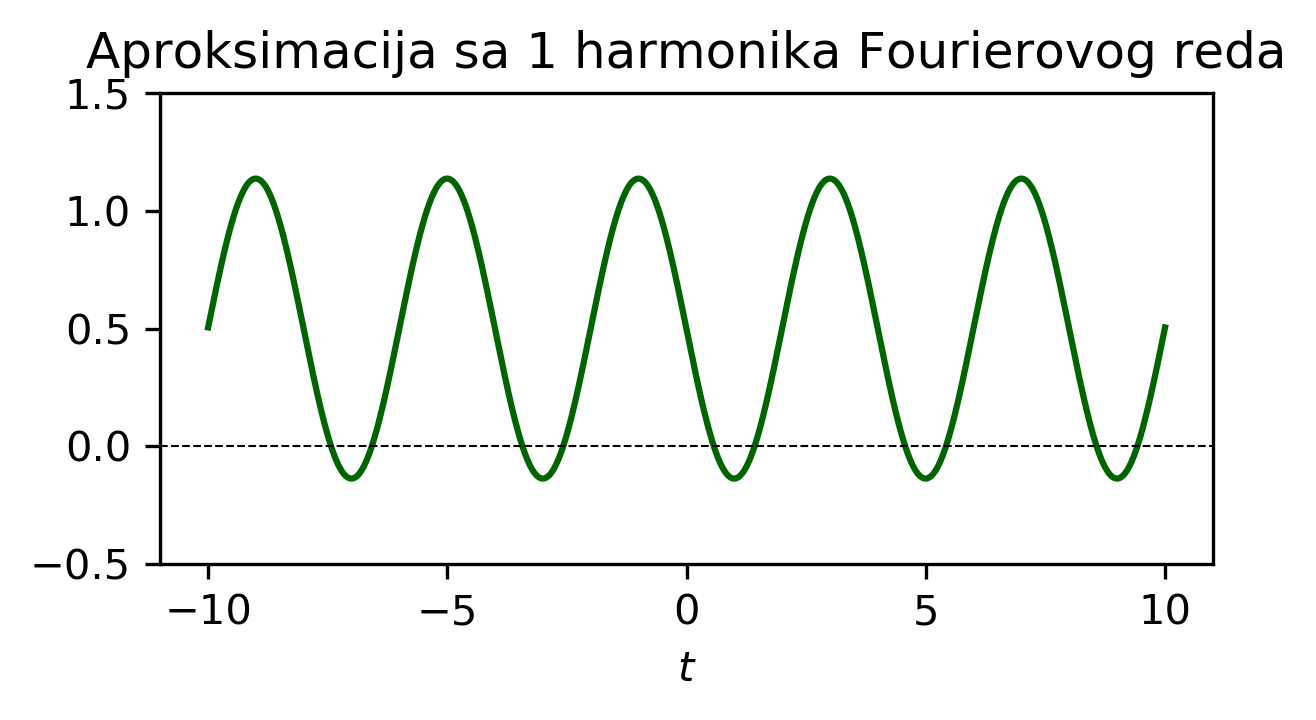

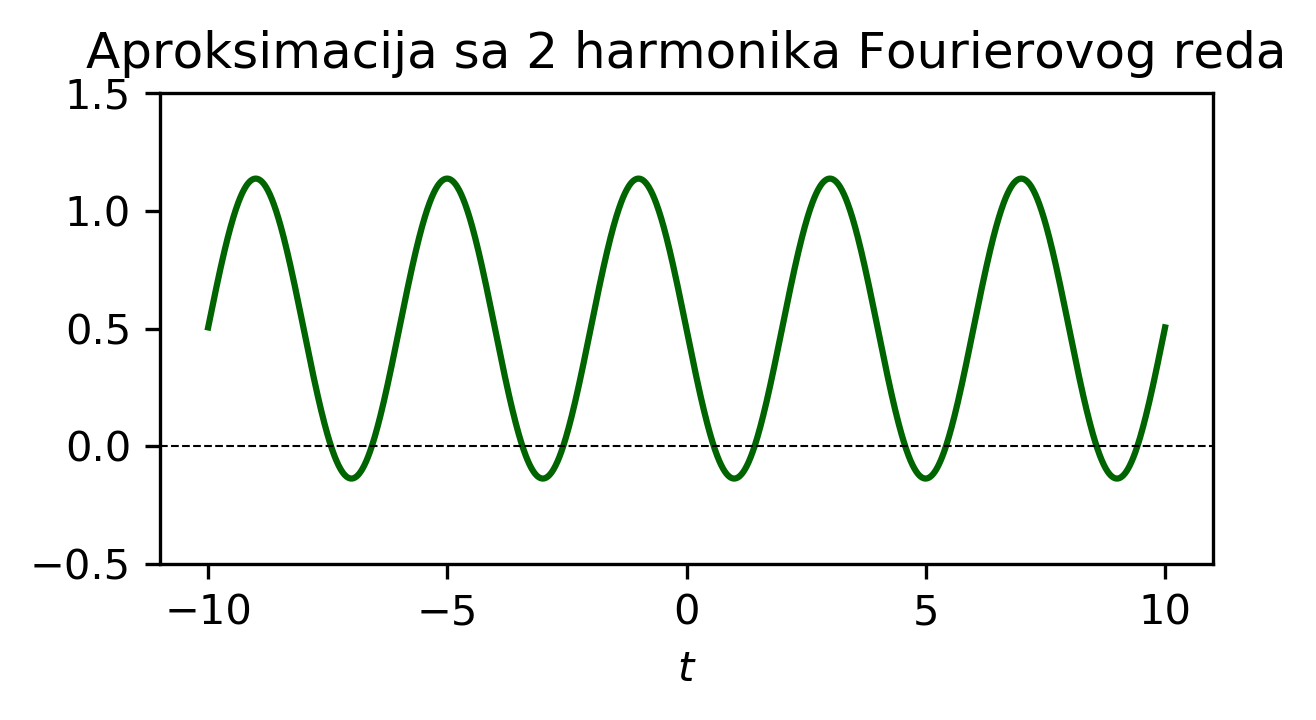

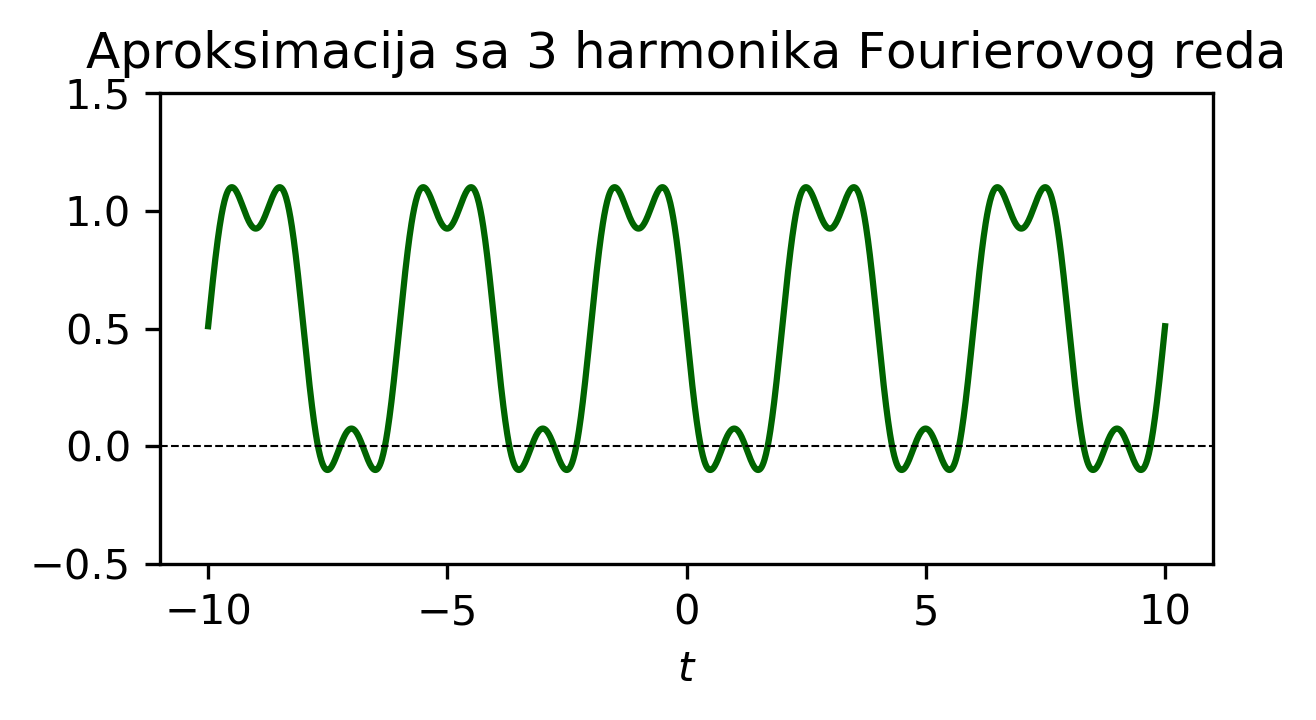

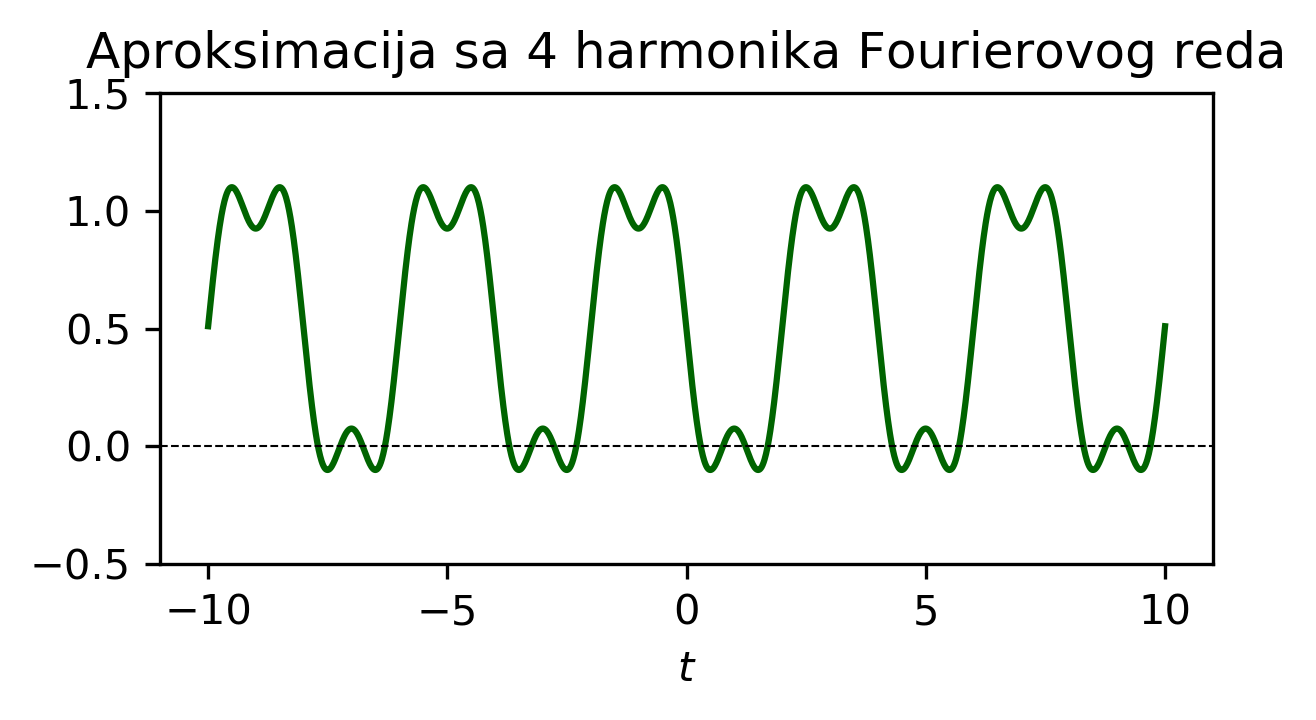

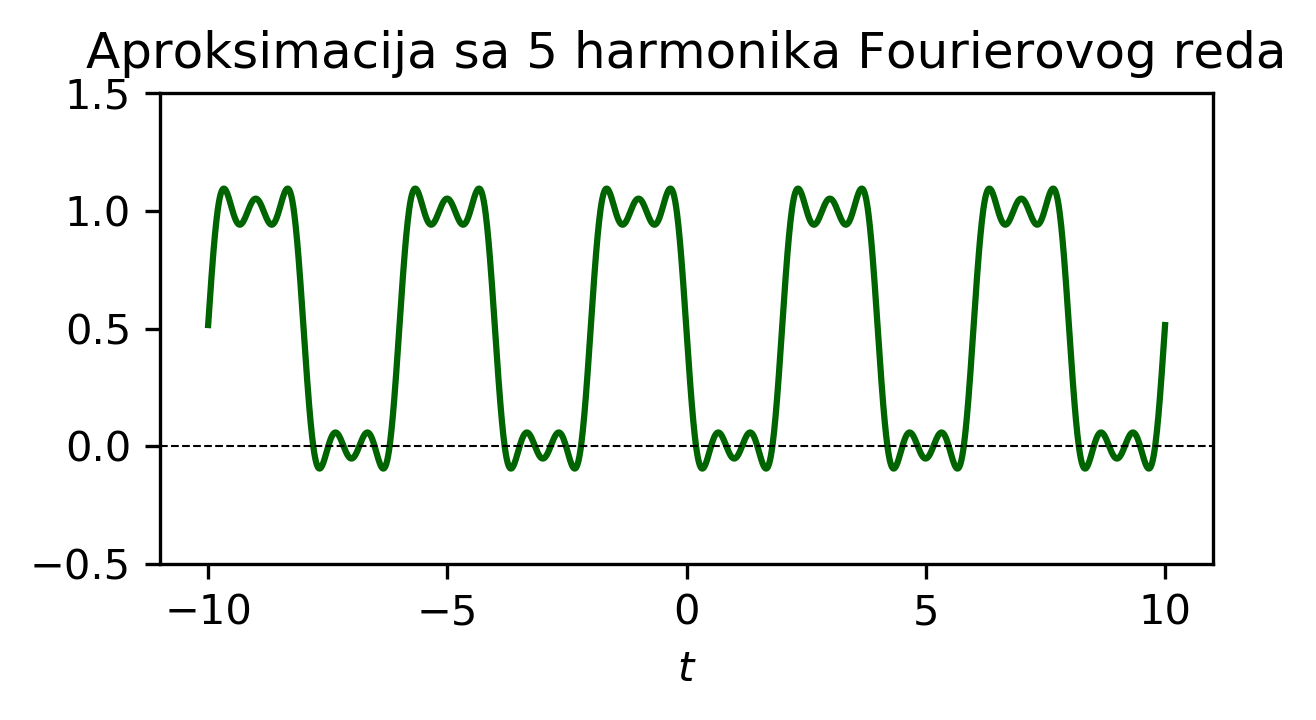

In [9]:
aproks = ts / per * np.sum(osn)   # nulti harmonik (DC komponenta)

sis.dijagram(t, x, 
            ylim=(-.5, 1.5),
            naslov='Originalna periodicka funkcija $f(t)$')

sis.dijagram(t, aproks * np.ones(len(t)), 
             ylim=(-.5, 1.5),
             naslov='Istosmjerna komponenta periodicke funkcije')

# aproksimacija sa k = 1, 2, ..., br harmonika
a = np.zeros(br)
b = np.zeros(br)

for k in range(1, br + 1):
    a[k-1] = 2 * ts / per * np.sum(osn * np.cos(k * w0 * t))
    b[k-1] = 2 * ts / per * np.sum(osn * np.sin(k * w0 * t))
    aproks = aproks + (a[k-1] * np.cos(k * w0 * t)
                        + b[k-1] * np.sin(k * w0 * t))

    sis.dijagram(t, aproks, 
                 ylim=(-.5, 1.5),
                 naslov=f'Aproksimacija sa {k} harmonika Fourierovog reda')

In [10]:
# =========================================================
# Kod 5.5 - Spektar periodicke funkcije f(t)
# =========================================================

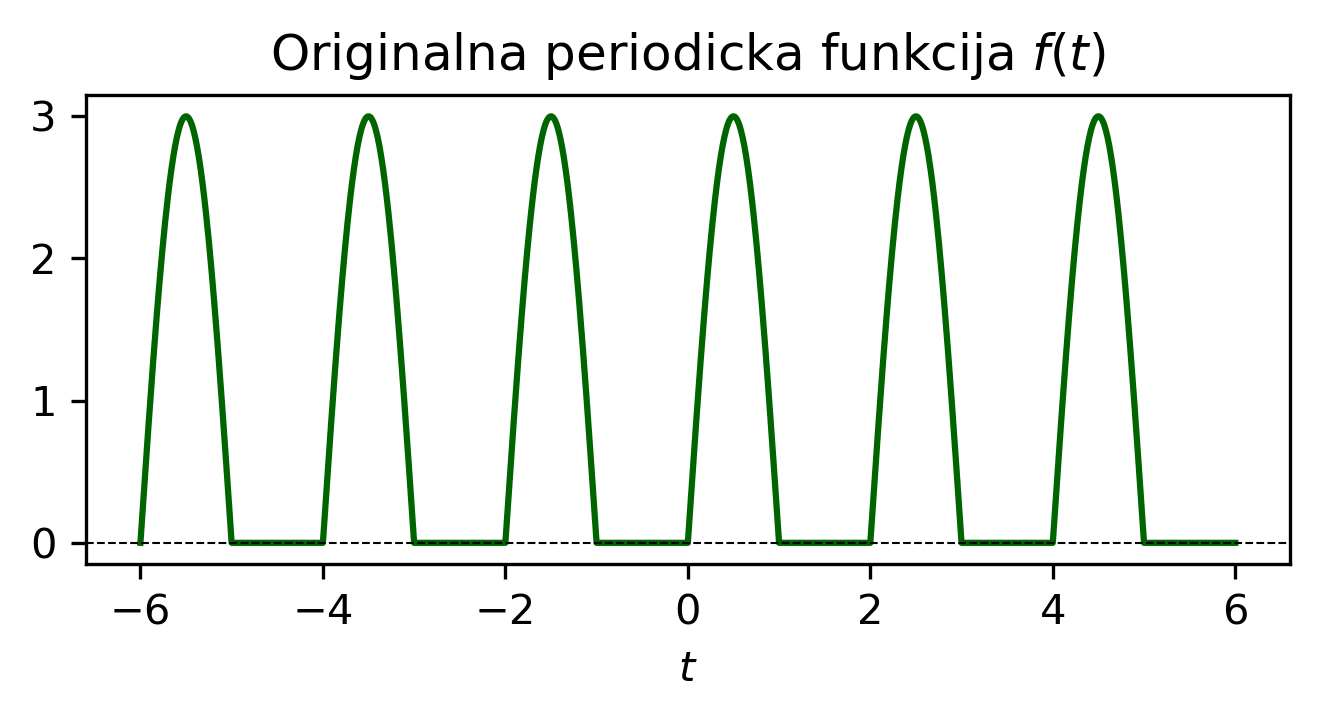

In [11]:
br   = 5       # broj harmonika (spektar od -br do +br)
ts   = 0.01    # vremenski korak
per  = 2       # period signala
t_start, t_end = -6, 6

t = np.arange(t_start, t_end + ts, ts)

# formiranje periodicke funkcije
y = 3 * np.sin(np.pi * t)
x = np.zeros(len(t))
gr = int(per / ts)          # broj tacaka jednog perioda
sirina = gr // 2            # sirina impulsa = pola perioda

for t0 in np.arange(t_start, t_end, per):
    idx = int((t0 - t_start) / ts)
    x[idx:idx + sirina] = y[idx:idx + sirina]

sis.dijagram(t, x, naslov=r'Originalna periodicka funkcija $f(t)$')

In [12]:
# =========================================================
# Kod 5.6 - Racunanje i prikaz spektra
# =========================================================

Koeficijenti Ck:
  C[-5] = 0.0000-0.0000j
  C[-4] = -0.0637+0.0000j
  C[-3] = 0.0000-0.0000j
  C[-2] = -0.3184+0.0000j
  C[-1] = 0.0000+0.7500j
  C[+0] = 0.9549+0.0000j
  C[+1] = 0.0000-0.7500j
  C[+2] = -0.3184-0.0000j
  C[+3] = 0.0000+0.0000j
  C[+4] = -0.0637-0.0000j
  C[+5] = 0.0000+0.0000j

Amplitudni spektar |Ck|:
  |C[-5]| = 0.0000
  |C[-4]| = 0.0637
  |C[-3]| = 0.0000
  |C[-2]| = 0.3184
  |C[-1]| = 0.7500
  |C[+0]| = 0.9549
  |C[+1]| = 0.7500
  |C[+2]| = 0.3184
  |C[+3]| = 0.0000
  |C[+4]| = 0.0637
  |C[+5]| = 0.0000


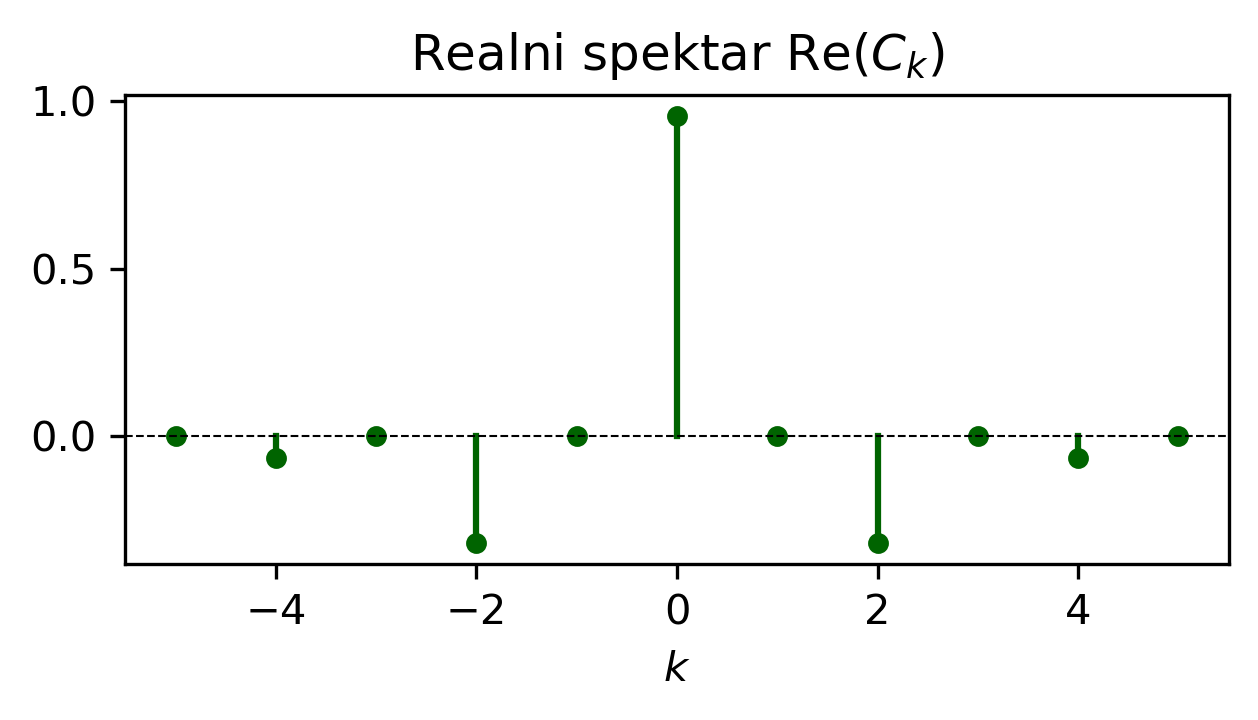

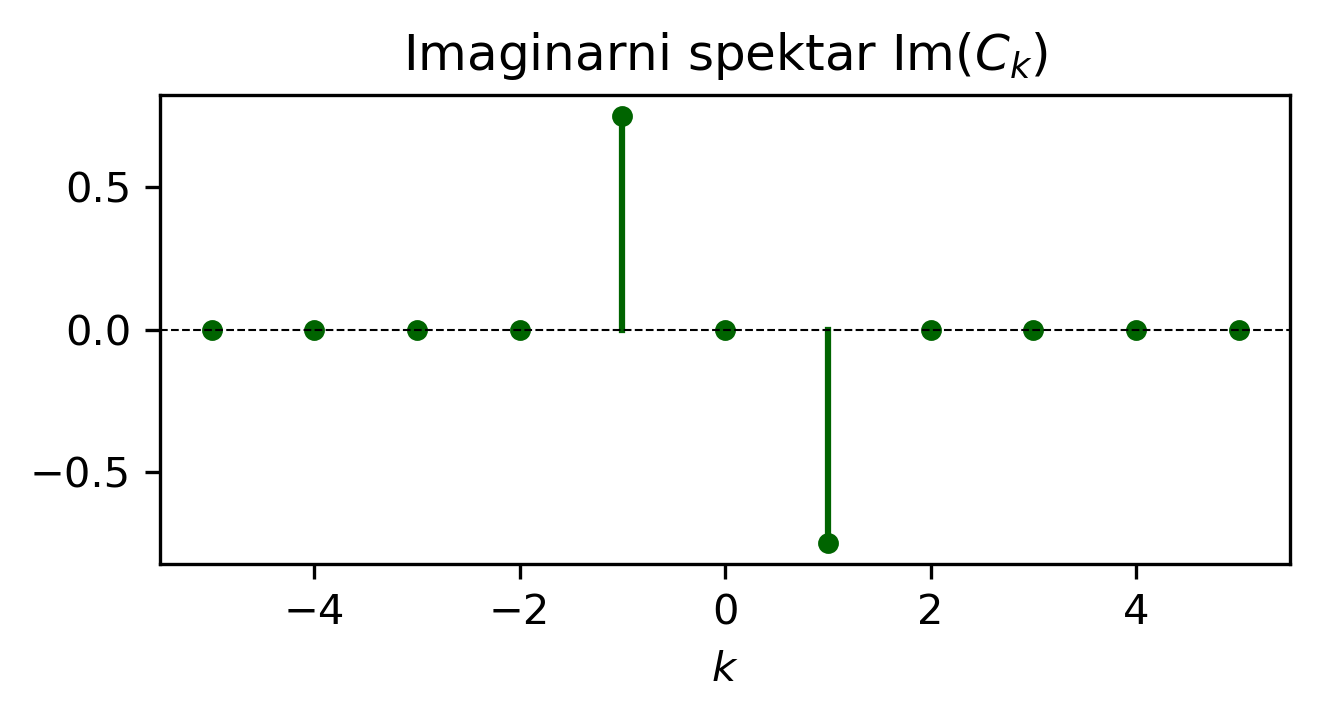

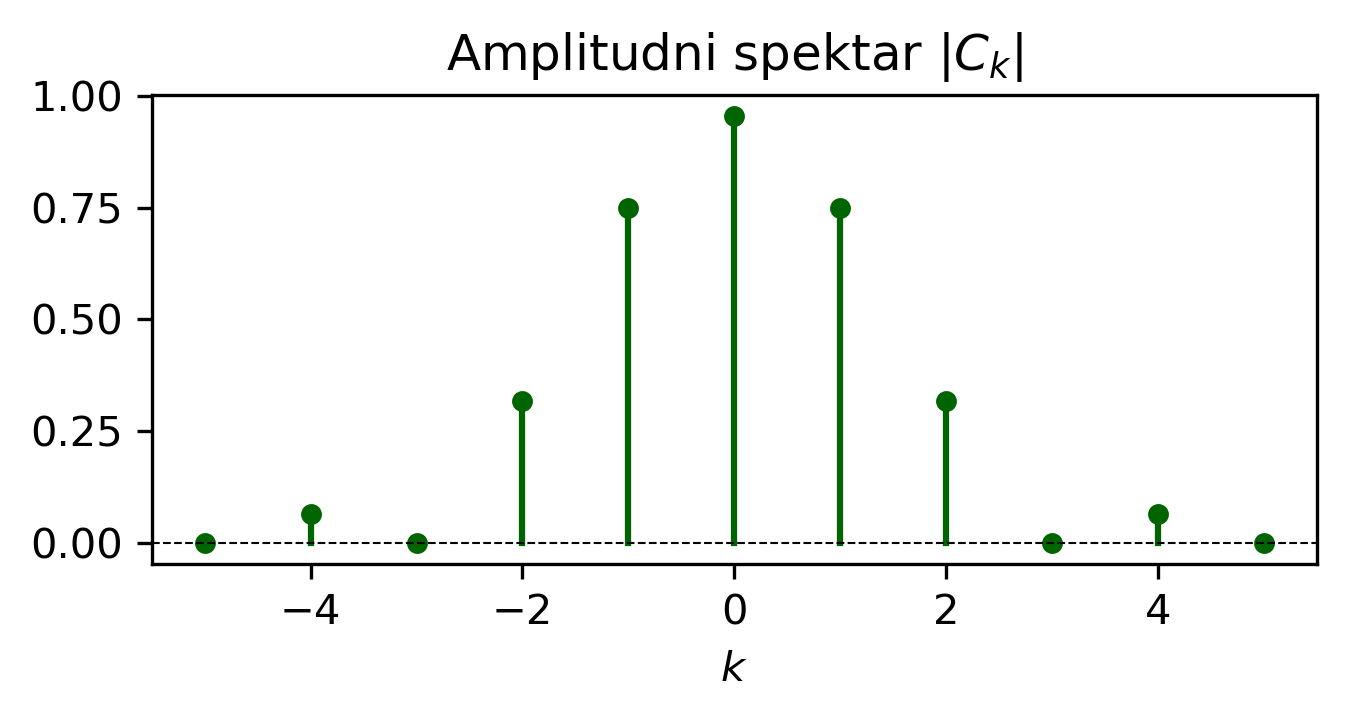

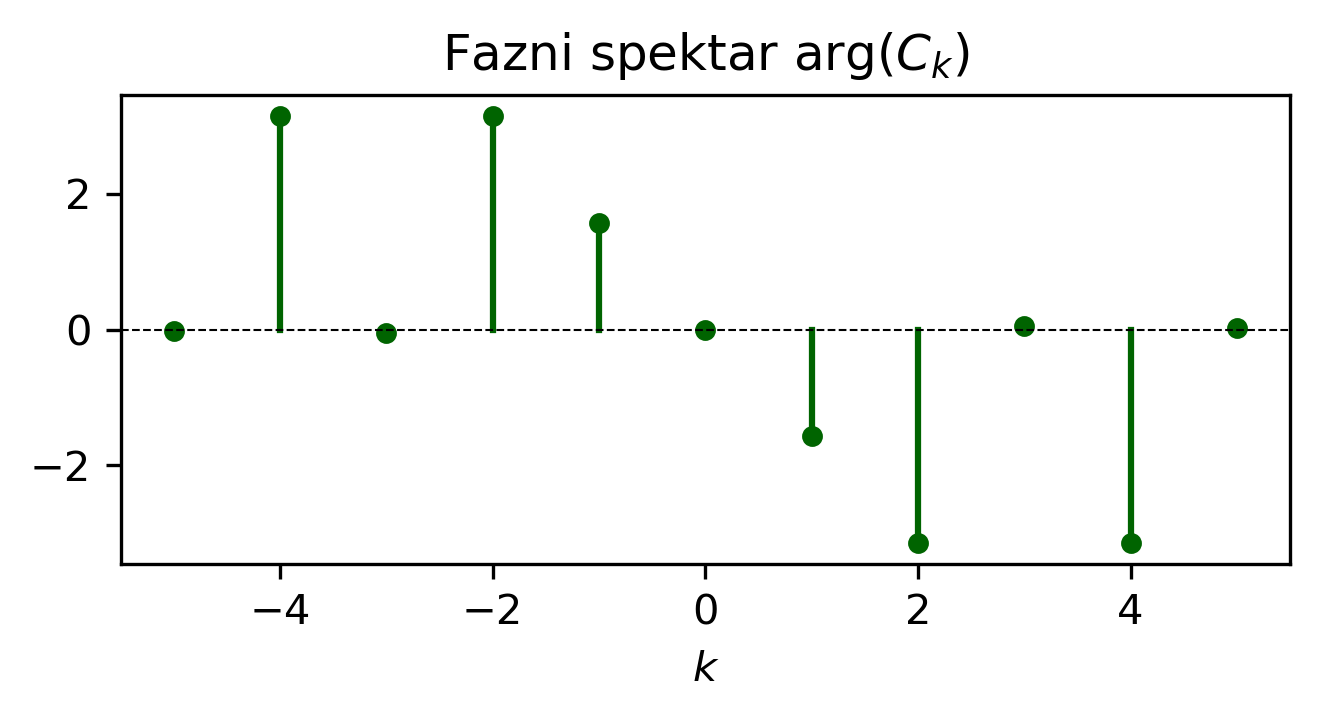

In [13]:
w0 = 2 * np.pi / per
om = np.arange(-br, br + 1)
c  = np.zeros(2 * br + 1, dtype=complex)

# jedan period funkcije pocevsi od t=0
idx0  = int((0 - t_start) / ts)
t_per = t[idx0:idx0 + gr]
x_per = x[idx0:idx0 + gr]

for k in range(-br, br + 1):
    kompl = np.exp(-1j * k * w0 * t_per)
    c[k + br] = ts / per * np.sum(x_per * kompl)

print("Koeficijenti Ck:")
for k in range(-br, br + 1):
    print(f"  C[{k:+d}] = {c[k+br]:.4f}")

print("\nAmplitudni spektar |Ck|:")
for k in range(-br, br + 1):
    print(f"  |C[{k:+d}]| = {abs(c[k+br]):.4f}")

# realni i imaginarni spektar
sis.dijagram(om, np.real(c), 
             tip='uzorci', x_labela=r'$k$', 
             naslov=r'Realni spektar $\mathrm{Re}(C_k)$')

sis.dijagram(om, np.imag(c), 
             tip='uzorci', x_labela=r'$k$', 
             naslov=r'Imaginarni spektar $\mathrm{Im}(C_k)$')
 
# amplitudni i fazni spektar
sis.dijagram(om, x=np.abs(c), 
             tip='uzorci', x_labela=r'$k$',
             naslov=r'Amplitudni spektar $|C_k|$') 

sis.dijagram(om, x=np.angle(c), 
             tip='uzorci', x_labela=r'$k$',
             naslov=r'Fazni spektar $\arg(C_k)$') 